In [ ]:
%pip install scikit-learn

In [2]:
#k-NN

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

# Carga de datos
data = load_digits()
Y = data["target"]
X = data["data"]

# División de los datos
X_train, X_test, Y_train, Y_test = train_test_split(X, Y)

# Instanciación y entrenamiento
knn = KNeighborsClassifier(n_neighbors=3, metric="euclidean")
knn.fit(X_train, Y_train)

# Tasa de acierto
print(knn.score(X_test, Y_test))

0.9755555555555555


In [1]:
#SVM

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC

# Carga y división de datos
data = load_digits()
Y = data["target"]
X = data["data"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y)

# Instanciación y entrenamiento
svmPoly = SVC(kernel="poly", degree=3, coef0=0)
svmPoly.fit(X_train, Y_train)

lsvm = LinearSVC()
lsvm.fit(X_train, Y_train)

# Tasas de acierto
print(svmPoly.score(X_test, Y_test))
print(lsvm.score(X_test, Y_test))

0.9911111111111112
0.9488888888888889


In [14]:
#PCA

from sklearn.decomposition import PCA
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
import numpy as np

# Carga y división de datos
data = load_digits()
X = data["data"]
Y = data["target"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y)

# Centrado de las muestras (paso fundamental para PCA)
media = np.mean(X_train, axis=0)
X_train_centered = X_train - media
X_test_centered = X_test - media

# 1. Aplicar PCA (reducimos de 64 píxeles a 20 componentes principales)
pca = PCA(n_components=20)
pca.fit(X_train_centered)
X_train_pca = pca.transform(X_train_centered)
X_test_pca = pca.transform(X_test_centered)

# 2. Usar un clasificador clásico sobre los datos reducidos
svm_pca = SVC(kernel="poly", degree=2, coef0=0)
svm_pca.fit(X_train_pca, Y_train)

# Tasa de acierto final del modelo completo
print(svm_pca.score(X_test_pca, Y_test))

0.9822222222222222


In [ ]:
%pip install tensorflow

In [27]:
#Red Neuronal

from keras.models import Sequential
from keras.layers import Dense, Activation
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import numpy as np

# Carga y división de datos
data = load_digits()
X = data["data"]
Y = data["target"]
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4)

# Codificación One-hot
Y_train_ohe = np.zeros((Y_train.shape[0], 10))
Y_test_ohe = np.zeros((Y_test.shape[0], 10))
for i in range(Y_train.shape[0]):
    Y_train_ohe[i, Y_train[i]] = 1
for i in range(Y_test.shape[0]):
    Y_test_ohe[i, Y_test[i]] = 1

# Definición de la red neuronal
model = Sequential()
model.add(Dense(100, input_dim=64, activation="sigmoid"))
model.add(Dense(10, activation="softmax"))

# Compilación y entrenamiento
model.compile(loss='mse', optimizer='RMSprop', metrics=['accuracy'])
model.fit(X_train, Y_train_ohe, epochs=10, batch_size=32)

# Función de error y tasa de acierto
print(model.evaluate(X_test, Y_test_ohe, batch_size=100))
# print(model.summary())

Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3581 - loss: 0.0810 
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7319 - loss: 0.0571
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8451 - loss: 0.0393
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8683 - loss: 0.0291
Epoch 5/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9351 - loss: 0.0218
Epoch 6/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9471 - loss: 0.0166
Epoch 7/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9620 - loss: 0.0131
Epoch 8/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9712 - loss: 0.0108
Epoch 9/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9722 - loss: 0.0089
Epoch 10/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9824 - loss: 0.0076
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9569 - loss: 0.0099  
[0.009862562641501427, 0.9568845629692078]


In [ ]:
%pip install matplotlib

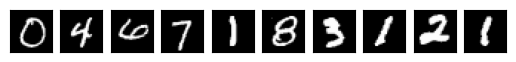

c:\Users\usuario\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 19s 29ms/step - accuracy: 0.8002 - loss: 0.7695
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.9141 - loss: 0.2983
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 17s 29ms/step - accuracy: 0.9303 - loss: 0.2396
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 23s 33ms/step - accuracy: 0.9413 - loss: 0.2018
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - accuracy: 0.9492 - loss: 0.1739
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 21s 32ms/step - accuracy: 0.9553 - loss: 0.1537
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.9605 - loss: 0.1378
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 19s 28ms/step - accuracy: 0.9638 - loss: 0.1247
Epoch 9/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 18s 31ms/step - accuracy: 0.9667 - loss: 0.1144
Epoch 10/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 19s 31ms/step - accuracy: 0.9697 - loss: 0.1051
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9720 - loss: 0.0981
[0.09807229042053223, 0.972000002861023]


In [1]:
# Red Convolucional 28x28 MNIST

from keras.models import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten
from keras.datasets import mnist
import keras.backend as K
import numpy as np
import matplotlib.pyplot as plt

# 1. Carga de datos usando MNIST (28x28) en lugar de load_digits
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# 1.1. Visualización de 10 dígitos 
f, axes = plt.subplots(1, 10)
for ax in axes.ravel():
    ax.imshow(X_train[np.random.randint(60000)], cmap="gray")
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

# 2. Redimensionamiento para la CNN y normalización [0, 1]
X_train = X_train.reshape(X_train.shape[0], 28, 28, 1) / 255.
X_test = X_test.reshape(X_test.shape[0], 28, 28, 1) / 255.

# 3. Codificación One-Hot
from keras.utils import to_categorical
Y_train_ohe = to_categorical(Y_train, num_classes=10)
Y_test_ohe = to_categorical(Y_test, num_classes=10)

# 4. Definición del modelo secuencial
model = Sequential()
model.add(Conv2D(25, kernel_size=(5, 5), padding="same", activation="relu", input_shape=(28, 28, 1)))
model.add(MaxPooling2D(padding="same"))
model.add(Flatten())
model.add(Dense(400, activation="relu"))
model.add(Dense(10, activation="softmax"))

# 5. Compilación y entrenamiento
model.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])
model.fit(X_train, Y_train_ohe, epochs=10, batch_size=100)

# 6. Evaluación
print(model.evaluate(X_test, Y_test_ohe))


In [ ]:
# Red monocapa MNIST

from keras.models import Sequential
from keras.layers import Dense
from keras.datasets import mnist
from keras.utils import to_categorical

# 1. Carga de datos
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# 2. Aplanado de las imágenes (Flatten manual)
# Transformamos la matriz de 28x28 a un vector de 784 variables
X_train_mlp = X_train.reshape(X_train.shape[0], 784) / 255.
X_test_mlp = X_test.reshape(X_test.shape[0], 784) / 255.

# 3. Codificación One-Hot de las etiquetas
Y_train_ohe = to_categorical(Y_train, num_classes=10)
Y_test_ohe = to_categorical(Y_test, num_classes=10)

# 4. Definición de la arquitectura MLP (Idéntica al apartado 4.3.1)
model_mlp = Sequential()
# Capa oculta única: 100 neuronas y activación sigmoide
model_mlp.add(Dense(100, activation="sigmoid", input_shape=(784,))) 
# Capa de salida: 10 neuronas y activación softmax
model_mlp.add(Dense(10, activation="softmax"))

# 5. Compilación y entrenamiento
# Usamos SGD como optimizador, igual que en el manual
model_mlp.compile(loss='categorical_crossentropy', optimizer='sgd', metrics=['accuracy'])

print("Entrenando el Perceptrón Multicapa de 1 capa...")
# Entrenamos con 10 épocas y batch_size de 100, igual que la CNN del apartado 4.4.2
model_mlp.fit(X_train_mlp, Y_train_ohe, epochs=10, batch_size=100)

# 6. Evaluación final
loss, accuracy = model_mlp.evaluate(X_test_mlp, Y_test_ohe)
print(f"\nPrecisión del MLP (1 capa oculta) en test: {accuracy:.4f}")

Entrenando el Perceptrón Multicapa de 1 capa...
Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 93s 6ms/step - accuracy: 0.5358 - loss: 1.9825
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7502 - loss: 1.4047
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8009 - loss: 1.0474
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8278 - loss: 0.8446
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8445 - loss: 0.7222
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8557 - loss: 0.6417
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8638 - loss: 0.5848
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8712 - loss: 0.5425
Epoch 9/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8754 - loss: 0.5097
Epoch 10/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8798 - loss: 0.4837
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8902 - loss: 0.4540

Precisión del 